This notebook will seek to answer Question 2 from our document A04: *What operating conditions show up most when a machine fails?* 

Below I'll provide the top 3 operating conditions (features) correlated with machine failure.  

The examined conditions include:
- Air temperature
- Process temperature
- Rotational Speed
- Torque
- Tool wear

### Mutual information classifier
Initially, I planned to use metrics driven from our logistic regression model, but I believe the question is better served by using a mutual information classifier utilizing all 10,000 data points. This classifier is not being used for predictions, but will instead be used to help identify correlation. This classifier is especially useful for features that can be correlated with failure in a non-linear way like temperature extremes.

In [38]:
# imports
import pipeline
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.feature_selection import mutual_info_classif

In [39]:
df = pipeline.load_data()

X = df[pipeline.PREDICTORS]
y = df[pipeline.TARGET]

# calculate MI across the full dataset
mi_scores = mutual_info_classif(X, y, random_state=42)

# top 3 ranking
ranking_df = pd.DataFrame({
    'feature': pipeline.PREDICTORS,
    'mutual_information': mi_scores
}).sort_values(by='mutual_information', ascending=False).reset_index(drop=True)

print("Top Ranked Failure Correlations:")
print(ranking_df)


# get top 3
top_3 = ranking_df['feature'].head(3).tolist()

# compare avg conditions for normal vs failed machines
conditions = df.groupby(pipeline.TARGET)[top_3].mean().T
conditions.columns = ['Normal Operation', 'Failure Event']
conditions['Difference'] = abs((conditions['Failure Event'] - conditions['Normal Operation']))
conditions['Difference (%)'] = ((conditions['Failure Event'] - conditions['Normal Operation']) / conditions['Normal Operation']) * 100

print("\nAverage Operating Conditions:")
print(conditions)

Top Ranked Failure Correlations:
               feature  mutual_information
0               Torque            0.047131
1     Rotational speed            0.035788
2            Tool wear            0.009603
3      Air temperature            0.007452
4  Process temperature            0.004626

Average Operating Conditions:
                  Normal Operation  Failure Event  Difference  Difference (%)
Torque                   39.629655      50.168142   10.538486       26.592425
Rotational speed       1540.260014    1496.486726   43.773289       -2.841942
Tool wear               106.693717     143.781711   37.087994       34.761179


Looking at the results, **Torque** is correlated most closely with machine failure, followed by **Rotational Speed** and **Tool Wear** as a distant third. It should be noted that this examination does not take into account the influence of combined features, such as temperature deltas, and the low MI scores across all individual features reflects this.

Examining the average operating conditions for the top 3 shows that the average feature measurement for normal operating conditions and failure conditions. 
- For torque, this failure conditions are roughly **10.53 Nm (26.59%) higher** than normal.
- For Rotational speed, failure conditions are measured around **43.77 rpm (-2.84%) lower** than normal operation.
- For Tool wear, failure conditions are on average **37.087 minutes (34.76%) more** than normal. 

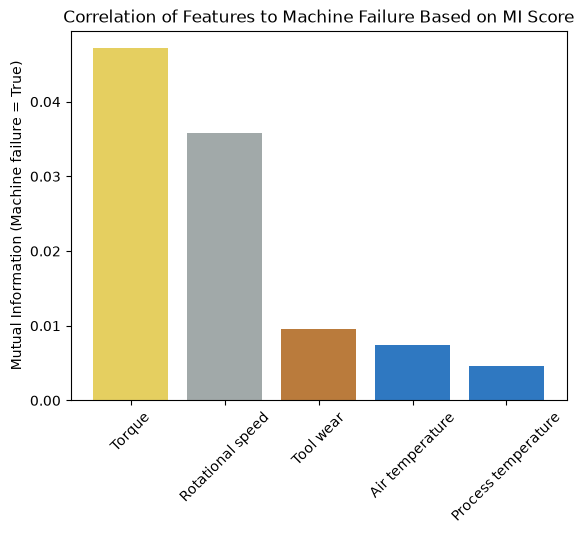

In [ ]:
bar_colors = ["#e5cf60", "#a1a9a9", "#BA7B3C","#2F78C1", "#2F78C1"]

# chart ranked features and save to data/outputs/
plt.bar(ranking_df['feature'],ranking_df['mutual_information'], color=bar_colors)
plt.ylabel('Mutual Information (Machine failure = True)')
plt.title('Correlation of Features to Machine Failure Based on MI Score')
plt.xticks(rotation=45)

# save and plot
plt.savefig(pipeline.OUTPUTS_DATA_DIR / 'Q2_failure_correlation.png', bbox_inches = 'tight')
plt.show()
